# PCA-Net

This notebook implements the **PCA-Net** surrogate (see Section 4.3) for the parametric diffusion problem. The surrogate adheres to the encoder-decoder architecture and is given as 
$$
\hat{\mathcal{G}} = \mathcal{D} \circ g_{\boldsymbol{\theta}} \circ \mathcal{E} : \mathcal{X} \to \mathcal{Y},
$$
for an encoder $\mathcal{E}: \mathcal{X} \to \mathbb{R}^{d_\mathcal{X}}$ and decoder $\mathcal{D}: \mathbb{R}^{d_\mathcal{Y}} \to \mathcal{Y}$. The mapping $g_{\boldsymbol{\theta}}: \mathbb{R}^{d_\mathcal{X}} \to \mathbb{R}^{d_\mathcal{Y}}$ is a feed-forward neural network.

For the following experiments, we choose the same encoder $\mathcal{E}$ and decoder $\mathcal{D}$ as in `2_Interpolation.ipynb`.

In [1]:
import time
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 12})

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import error

from importer import import_notebook
import_notebook('0_Diffusion.ipynb', globals())       # provides: Grid, Diffusion
import_notebook('1_Representation.ipynb', globals())  # provides: Encoder, Decoder

In [2]:
d_in     = 50                           # input dimension (sine-series modes)
d_out    = 50                           # output dimension (PCA modes)
n_epochs = 500                          # training epochs per run
n_test   = 200                          # number of test samples
n_trains = [100, 200, 500, 1000, 2000]  # number of training samples
n_max    = max(n_trains)                # maximal number of training samples
layers   = [64, 64]                     # hidden layer widths
grid     = Grid(128)                    # discretisation of the PDE
torch.manual_seed(0)
rng      = np.random.default_rng(0)

## 1. The FFN

The approximator $g_{\boldsymbol{\theta}} : \mathbb{R}^{d_\mathcal{X}} \to
\mathbb{R}^{d_\mathcal{Y}}$ is a fully-connected network:
$$
  g_{\boldsymbol{\theta}}(\bar{\mathbf{x}})
  = W_L \circ \sigma \circ W_{L-1} \circ \cdots \circ \sigma \circ W_0 (\bar{\mathbf{x}}),
  \qquad \sigma = \mathrm{GELU}.
$$
Each $W_\ell(\mathbf{x}) = A_\ell \mathbf{x} + \mathbf{b}_\ell$ is an affine map with weight matrix $A_\ell$ and bias $\mathbf{b}_\ell$; together the $\{A_\ell, \mathbf{b}_\ell\}$
form the trainable parameter vector $\boldsymbol{\theta}$.
$\sigma$ is an activation function acting pointwise. Here, we use the Gaussian Error Linear Unit $\sigma(x) = \mathrm{GELU}(x) = x\Phi(x)$, where $\Phi$ is the standard normal cumulative distribution function (for more details see [Hendrycks and Gimpel, 2023](https://arxiv.org/abs/1606.08415)). Compared to ReLU, GELU is smooth everywhere and has been found to train more reliably in practice.

The network is trained by minimising the MSE loss in the latent space,
$$
  \mathcal{L}(\boldsymbol{\theta}) =
  \frac{1}{n} \sum_{k=1}^n \| g_{\boldsymbol{\theta}}(\bar{\mathbf{x}}^{(k)}) - \bar{\mathbf{y}}^{(k)} \|^2,
$$
where $\bar{\mathbf{y}}^{(k)} = \mathcal{D}^{-1}(\mathcal{G}(\mathcal{E}^{-1}(\bar{\mathbf{x}}^{(k)})))$ are the encoded training targets, using the Adam optimiser with learning rate $10^{-3}$ and batch size 32.

In [3]:
#EXPORT

class FFN:
    """
    Feed-forward neural network surrogate in the PCA-encoded latent space (Section 4.3).

    Parameters
    ----------
    d_in   : int        -- input dimension
    d_out  : int        -- output dimension (PCA rank)
    layers : list[int]  -- hidden layer widths
    """

    def __init__(self, d_in, d_out, layers):
        parts = []
        prev  = d_in
        for width in layers:
            parts += [nn.Linear(prev, width), nn.GELU()]
            prev   = width
        parts.append(nn.Linear(prev, d_out))
        self.network = nn.Sequential(*parts)

    def forward(self, x):
        """ Evaluate the network.  x: numpy array or tensor -> numpy array. """
        was_numpy = isinstance(x, np.ndarray)
        if was_numpy:
            x = torch.tensor(x, dtype=torch.float32)
        self.network.eval()
        with torch.no_grad():
            out = self.network(x)
        return out.numpy() if was_numpy else out

    def train(self, data_train, data_test=None, n_epochs=500, verbose=True):
        """
        Train with Adam (lr=1e-3, batch_size=32).
        data_train / data_test : dicts with keys 'x' (inputs) and 'y' (targets).
        Returns a loss history dict with keys 'train' and 'test'.
        """
        t0   = time.perf_counter()
        to_t = lambda a: torch.tensor(a, dtype=torch.float32)
        ds_train = TensorDataset(to_t(data_train['x']), to_t(data_train['y']))
        dl_train = DataLoader(ds_train, batch_size=32, shuffle=True)
        dl_test  = None
        if data_test is not None:
            ds_test = TensorDataset(to_t(data_test['x']), to_t(data_test['y']))
            dl_test = DataLoader(ds_test, batch_size=len(ds_test))

        loss_fn   = nn.MSELoss()
        optimizer = optim.Adam(self.network.parameters(), lr=1e-3)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
        history   = {'train': np.zeros(n_epochs), 'test': np.zeros(n_epochs)}

        for epoch in range(n_epochs):
            # test evaluation (on network state before this epoch's updates)
            if dl_test is not None:
                self.network.eval()
                with torch.no_grad():
                    for bx, by in dl_test:
                        history['test'][epoch] = loss_fn(self.network(bx), by).item()

            # training step
            self.network.train()
            for bx, by in dl_train:
                optimizer.zero_grad()
                loss = loss_fn(self.network(bx), by)
                loss.backward()
                optimizer.step()
                history['train'][epoch] += loss.item() * len(bx)
            history['train'][epoch] /= len(ds_train)
            scheduler.step()

        if verbose:
            print(f'Training (n={len(ds_train)}, {n_epochs} epochs):  {time.perf_counter() - t0:.0f}s')
        return history

## 2. Learning Curve

We first illustrate the training process for a single configuration ($\alpha = 2$,
$n = 500$ training samples). The plot shows the loss $\mathcal{L}(\boldsymbol{\theta})$ over training epochs.

In [4]:
decay_ex   = 2
n_train_ex = 500

xb_ex  = rng.uniform(-1., 1., (n_train_ex + n_test, d_in))
y_ex  = np.array([Diffusion(coefficient=Encoder(parameter=xb, decay=decay_ex))(grid)
                  for xb in xb_ex])
coder_ex = Decoder(rank=d_out, samples=y_ex[:n_train_ex].T)
yb_ex    = coder_ex.analyse(y_ex)

data_train_ex = {'x': xb_ex[:n_train_ex],  'y': yb_ex[:n_train_ex]}
data_test_ex  = {'x': xb_ex[n_train_ex:],  'y': yb_ex[n_train_ex:]}

net_ex  = FFN(d_in, d_out, layers)
history = net_ex.train(data_train_ex, data_test_ex, n_epochs=n_epochs)

Training (n=500, 500 epochs):  8s


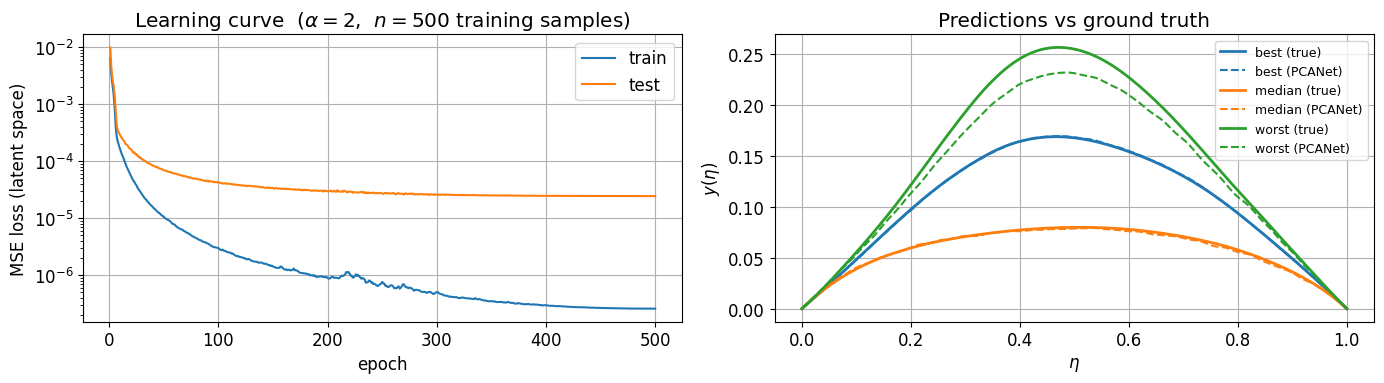

In [5]:
yb_pred  = net_ex.forward(xb_ex[n_train_ex:])
y_pred   = coder_ex.synthesise(yb_pred)
y_test   = y_ex[n_train_ex:]
rel_l2   = error.l2_rel(y_test, y_pred, per_sample=True)

fig, axs = plt.subplots(1, 2, figsize=(14, 4))

# -- learning curve --
epochs = np.arange(1, n_epochs + 1)
axs[0].semilogy(epochs, history['train'], label='train')
axs[0].semilogy(epochs, history['test'],  label='test')
axs[0].set_xlabel('epoch'); axs[0].set_ylabel('MSE loss (latent space)')
axs[0].set_title(rf'Learning curve  ($\alpha={decay_ex}$,  $n={n_train_ex}$ training samples)')
axs[0].legend(); axs[0].grid()

# -- example predictions --
idx_med   = np.argsort(rel_l2)[len(rel_l2) // 2]
idx_best  = np.argmin(rel_l2)
idx_worst = np.argmax(rel_l2)
for idx, label in [(idx_best, 'best'), (idx_med, 'median'), (idx_worst, 'worst')]:
    line, = axs[1].plot(grid.nodes_bd, y_test[idx],  lw=2,   label=f'{label} (true)')
    axs[1].plot(grid.nodes_bd, y_pred[idx],  lw=1.5, ls='--', label=f'{label} (PCANet)', color=line.get_color())
axs[1].set_xlabel(r'$\eta$'); axs[1].set_ylabel(r'$y(\eta)$')
axs[1].set_title('Predictions vs ground truth')
axs[1].legend(fontsize=9); axs[1].grid()

plt.tight_layout()
plt.show()

## 3. Convergence with Training Data Size

We now study how the prediction error decreases as the number of training samples $n$ grows,
for three input-field smoothness levels $\alpha \in \{1, 2, 3\}$.

For each $\alpha$:
1. Draw $n_\mathrm{max}$ samples $\bar{\mathbf{x}} \sim \mathrm{Uniform}([-1,1]^{d_\mathcal{X}})$,
   compute $\mathcal{G}(\mathcal{E}^{-1}(\bar{\mathbf{x}}))$ for each, and fit the PCA decoder
   $\mathcal{D}$ of rank $d_\mathcal{Y}$;
2. Train a network $g_{\boldsymbol{\theta}}$ on the first $n$ samples for each $n$ in a
   log-spaced sequence up to $n_\mathrm{max}$;
3. Evaluate $\hat{\mathcal{G}} = \mathcal{D} \circ g_{\boldsymbol{\theta}} \circ \mathcal{E}$
   on $n_\mathrm{test}$ held-out samples and measure the relative $L^2$ error.

The decoder $\mathcal{D}$ is fixed (fitted on all $n_\mathrm{max}$ samples) so that only the
network training quality varies with $n$.

In [6]:
decays   = [1, 2, 3]

xb_test = rng.uniform(-1., 1., (n_test, d_in))

results  = {}  # decay -> (n_trains list, errors list)

for decay in decays:

    # --- generate training data and fit PCA basis ---
    xb_all   = rng.uniform(-1., 1., (n_max, d_in))
    y_all    = np.array([Diffusion(coefficient=Encoder(parameter=xb, decay=decay))(grid) for xb in xb_all])
    coder    = Decoder(rank=d_out, samples=y_all.T)
    yb_all   = coder.analyse(y_all)

    # --- reference solutions on the fixed test set ---
    y_test = np.array([Diffusion(coefficient=Encoder(parameter=xb, decay=decay))(grid) for xb in xb_test])

    # --- train a network for each n and record the error ---
    err_list = []
    for n_train in n_trains:
        print(f'Decay = {decay} / ', end='')
        net = FFN(d_in, d_out, layers)
        net.train({'x': xb_all[:n_train], 'y': yb_all[:n_train]}, n_epochs=n_epochs)
        y_pred = coder.synthesise(net.forward(xb_test))
        err_list.append(error.l2_rel(y_test, y_pred))
    results[decay] = (n_trains, err_list)

Decay = 1 / Training (n=100, 500 epochs):  2s
Decay = 1 / Training (n=200, 500 epochs):  2s
Decay = 1 / Training (n=500, 500 epochs):  18s
Decay = 1 / Training (n=1000, 500 epochs):  10s
Decay = 1 / Training (n=2000, 500 epochs):  19s
Decay = 2 / Training (n=100, 500 epochs):  2s
Decay = 2 / Training (n=200, 500 epochs):  3s
Decay = 2 / Training (n=500, 500 epochs):  7s
Decay = 2 / Training (n=1000, 500 epochs):  16s
Decay = 2 / Training (n=2000, 500 epochs):  33s
Decay = 3 / Training (n=100, 500 epochs):  2s
Decay = 3 / Training (n=200, 500 epochs):  6s
Decay = 3 / Training (n=500, 500 epochs):  9s
Decay = 3 / Training (n=1000, 500 epochs):  16s
Decay = 3 / Training (n=2000, 500 epochs):  32s


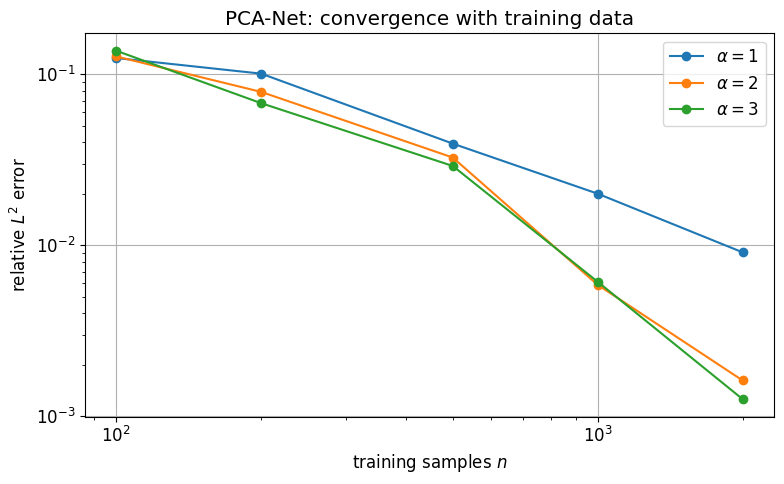

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

for decay in decays:
    ns, errs = results[decay]
    ax.loglog(ns, errs, marker='o', label=rf'$\alpha = {decay}$')

ax.set_title('PCA-Net: convergence with training data')
ax.set_xlabel('training samples $n$'); ax.set_ylabel('relative $L^2$ error')
ax.legend(); ax.grid(); plt.tight_layout()
plt.show()